# Week 3 · Math for ML: solutions
Nights 15–21 · 7–13 December 2026

Worked answers for `notebooks/week3_math_for_ml.ipynb`. Try each exercise yourself first; read a solution only after
20 minutes of being stuck, then close this file and retype it from memory.

Study guide: [Week 3 tab](https://claude.ai/artifact/5MJxvaW9sNxjp7rjmPWuCu#3e1e9b7c-5e48).

In [1]:
# Run this cell first (Shift+Enter). It finds your project folder and defines `check`,
# which prints "Correct" when an exercise works.
import math
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = ROOT / "data"


def _same(a, b, tol=1e-6):
    import math as _math
    import numbers as _numbers
    try:
        import numpy as _np
    except ImportError:
        _np = None
    if _np is not None and (isinstance(a, _np.ndarray) or isinstance(b, _np.ndarray)):
        a, b = _np.asarray(a), _np.asarray(b)
        if a.shape != b.shape:
            return False
        if a.dtype.kind in "biuf" and b.dtype.kind in "biuf":
            return bool(_np.allclose(a, b, rtol=1e-5, atol=tol))
        return bool((a == b).all())
    if isinstance(a, bool) or isinstance(b, bool):
        return a == b
    if isinstance(a, _numbers.Number) and isinstance(b, _numbers.Number):
        return _math.isclose(a, b, rel_tol=1e-5, abs_tol=tol)
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(_same(x, y, tol) for x, y in zip(a, b))
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(_same(a[k], b[k], tol) for k in a)
    return a == b


def check(label, actual, expected=True, tol=1e-6):
    """Run `actual` (usually a lambda) and print Correct if it equals `expected`."""
    try:
        got = actual() if callable(actual) else actual
    except NotImplementedError:
        print(f"⏳ Not done yet: {label}")
        return
    except Exception as error:  # show the problem without stopping the notebook
        print(f"❌ {label}: your code raised {type(error).__name__}: {error}")
        return
    if _same(got, expected, tol):
        print(f"✅ Correct: {label}")
    else:
        print(f"❌ {label}\n   expected: {expected!r}\n   got:      {got!r}")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Ready")

Ready


## Night 15 · Mon 7 Dec: Vectors and the dot product
A vector is a list of numbers. The dot product measures how much two vectors point the same way; cosine
similarity is that idea scaled to the range −1 to 1, and it's how AI search finds text with a similar meaning.

In [2]:
a = np.array([2, 1])
b = np.array([1, 3])
print("a + b =", a + b)
print("3 * a =", 3 * a)

a + b = [3 4]
3 * a = [6 3]


In [3]:
# 15.1 Length, dot product and cosine similarity
def vector_length(v):
    """Return the length of v. Hint: np.linalg.norm."""
    return float(np.linalg.norm(v))


def dot_by_hand(a, b):
    """Multiply matching entries and add them up, with a loop or sum(). No NumPy."""
    return sum(x * y for x, y in zip(a, b))


def cosine_similarity(a, b):
    """Return dot(a, b) / (length(a) * length(b))."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

check("length of [3, 4]", lambda: vector_length([3, 4]), 5.0)
check("dot_by_hand([1, 2, 3], [4, 5, 6])", lambda: dot_by_hand([1, 2, 3], [4, 5, 6]), 32)
check("same answer as np.dot", lambda: dot_by_hand([1, 2, 3], [4, 5, 6]) == np.dot([1, 2, 3], [4, 5, 6]), True)
check("at right angles: 0", lambda: cosine_similarity([1, 0], [0, 1]), 0.0)
check("same direction: 1", lambda: cosine_similarity([1, 1], [2, 2]), 1.0)
check("opposite: -1", lambda: cosine_similarity([1, 0], [-1, 0]), -1.0)

✅ Correct: length of [3, 4]
✅ Correct: dot_by_hand([1, 2, 3], [4, 5, 6])
✅ Correct: same answer as np.dot
✅ Correct: at right angles: 0
✅ Correct: same direction: 1
✅ Correct: opposite: -1


In [4]:
# A made-up embedding table. Real embeddings have hundreds of numbers learned from text;
# these 4 stand for roughly: royalty, male, female, fruit.
embeddings = {
    "king": np.array([1.0, 0.6, 0.1, 0.0]),
    "queen": np.array([1.0, 0.1, 0.6, 0.0]),
    "man": np.array([0.1, 0.8, 0.1, 0.0]),
    "woman": np.array([0.1, 0.1, 0.8, 0.0]),
    "mango": np.array([0.0, 0.0, 0.0, 1.0]),
    "apple": np.array([0.05, 0.0, 0.0, 0.9]),
}

In [5]:
# 15.2 Search by meaning
def closest_word(word, table):
    """Return the other word in `table` whose vector has the highest cosine similarity to `word`'s."""
    others = [w for w in table if w != word]
    return max(others, key=lambda w: cosine_similarity(table[word], table[w]))


def analogy(a, b, c, table):
    """Return the word closest to vector(a) - vector(b) + vector(c), leaving out a, b and c themselves."""
    target = table[a] - table[b] + table[c]
    candidates = [w for w in table if w not in (a, b, c)]
    return max(candidates, key=lambda w: cosine_similarity(target, table[w]))

check("closest to king", lambda: closest_word("king", embeddings), "queen")
check("closest to mango", lambda: closest_word("mango", embeddings), "apple")
check("king - man + woman", lambda: analogy("king", "man", "woman", embeddings), "queen")

✅ Correct: closest to king
✅ Correct: closest to mango
✅ Correct: king - man + woman


## Night 16 · Tue 8 Dec: Matrices as transformations
A matrix transforms vectors. Shapes (m, n) @ (n, p) give (m, p). A neural-network layer is a matrix multiply plus a bias.

In [6]:
# 16.1 Rotation
def rotate(point, degrees):
    """Rotate a 2-D point counter-clockwise around (0, 0). Build R = [[cos θ, -sin θ], [sin θ, cos θ]]
    with θ = math.radians(degrees), and return R @ point."""
    theta = math.radians(degrees)
    R = np.array([[math.cos(theta), -math.sin(theta)], [math.sin(theta), math.cos(theta)]])
    return R @ np.asarray(point, dtype=float)

check("rotate (1, 0) by 90°", lambda: rotate([1, 0], 90), np.array([0.0, 1.0]))
check("rotate (2, 0) by 180°", lambda: rotate([2, 0], 180), np.array([-2.0, 0.0]))

✅ Correct: rotate (1, 0) by 90°
✅ Correct: rotate (2, 0) by 180°


In [7]:
# 16.2 The shape rule, and matrix multiplication with plain loops
def result_shape(shape_a, shape_b):
    """Return the shape of A @ B as a tuple, or None when the inner sizes don't match."""
    return (shape_a[0], shape_b[1]) if shape_a[1] == shape_b[0] else None


def matmul_loops(A, B):
    """Multiply two matrices given as lists of lists, using three nested loops. No NumPy."""
    rows, inner, cols = len(A), len(B), len(B[0])
    result = [[0] * cols for _ in range(rows)]
    for i in range(rows):
        for j in range(cols):
            for k in range(inner):
                result[i][j] += A[i][k] * B[k][j]
    return result

check("(2, 3) @ (3, 4)", lambda: result_shape((2, 3), (3, 4)), (2, 4))
check("(2, 3) @ (2, 3) doesn't fit", lambda: result_shape((2, 3), (2, 3)), None)
check("2x2 by hand", lambda: matmul_loops([[1, 2], [3, 4]], [[5, 6], [7, 8]]), [[19, 22], [43, 50]])
check(
    "2x3 @ 3x2 matches NumPy",
    lambda: matmul_loops([[1, 2, 3], [4, 5, 6]], [[7, 8], [9, 10], [11, 12]]),
    (np.array([[1, 2, 3], [4, 5, 6]]) @ np.array([[7, 8], [9, 10], [11, 12]])).tolist(),
)

✅ Correct: (2, 3) @ (3, 4)
✅ Correct: (2, 3) @ (2, 3) doesn't fit
✅ Correct: 2x2 by hand
✅ Correct: 2x3 @ 3x2 matches NumPy


In [8]:
# 16.3 One neural-network layer on a batch of 3 examples with 2 inputs each
X = np.array([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
W = np.array([[0.5, -1.0, 2.0], [1.0, 0.0, -1.0]])  # 2 inputs -> 3 outputs
b = np.array([0.1, 0.2, 0.3])


def dense_layer(X, W, b):
    """Return X @ W + b: one row of outputs per example."""
    return X @ W + b


def relu(z):
    """Replace negative numbers with 0. Hint: np.maximum."""
    return np.maximum(0, z)

check("dense_layer", lambda: dense_layer(X, W, b), np.array([[2.6, -0.8, 0.3], [5.6, -2.8, 2.3], [8.6, -4.8, 4.3]]))
check("relu(dense_layer)", lambda: relu(dense_layer(X, W, b)), np.array([[2.6, 0.0, 0.3], [5.6, 0.0, 2.3], [8.6, 0.0, 4.3]]))

✅ Correct: dense_layer
✅ Correct: relu(dense_layer)


## Night 17 · Wed 9 Dec: Derivatives, or how fast things change
A derivative is a slope: how much the output moves when the input moves a little. At a minimum the slope is zero.

In [9]:
# 17.1 A numerical derivative
def numerical_derivative(f, x, h=1e-5):
    """Approximate f'(x) with the central difference (f(x + h) - f(x - h)) / (2 * h)."""
    return (f(x + h) - f(x - h)) / (2 * h)

check("slope of x² at x = 3 is 6", lambda: numerical_derivative(lambda x: x ** 2, 3.0), 6.0, tol=1e-4)
check("slope of sin at 0 is 1", lambda: numerical_derivative(np.sin, 0.0), 1.0, tol=1e-4)

✅ Correct: slope of x² at x = 3 is 6
✅ Correct: slope of sin at 0 is 1


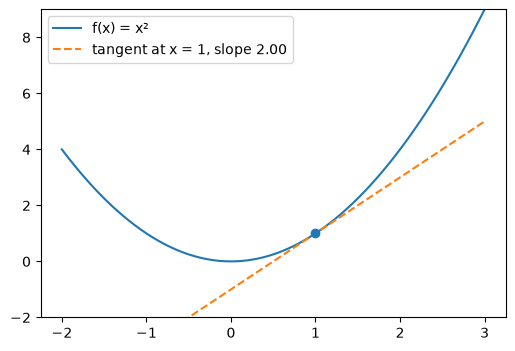

In [10]:
# 17.2 Plot f(x) = x² and its tangent line at x = 1: y = f(1) + slope * (x - 1)
f = lambda x: x ** 2
xs = np.linspace(-2, 3, 100)
fig, ax = plt.subplots(figsize=(6, 4))
slope = numerical_derivative(f, 1.0)
ax.plot(xs, f(xs), label="f(x) = x²")
ax.plot(xs, f(1.0) + slope * (xs - 1.0), "--", label=f"tangent at x = 1, slope {slope:.2f}")
ax.scatter([1.0], [f(1.0)], zorder=3)
ax.set_ylim(-2, 9)
ax.legend()
plt.show()

In [11]:
# 17.3 Walk downhill using only the sign of the slope
def lowest_point(f, start=5.0, step=0.01, max_steps=10_000):
    """Start at x = start. While the slope at x isn't close to 0 (abs(slope) < 1e-3),
    move x by `step` against the slope's sign. Return x rounded to 2 decimals."""
    x = start
    for _ in range(max_steps):
        slope = numerical_derivative(f, x)
        if abs(slope) < 1e-3:
            break
        x -= step * np.sign(slope)
    return round(float(x), 2)

check("the lowest point of (x - 2)² + 1 is at x = 2", lambda: lowest_point(lambda x: (x - 2) ** 2 + 1), 2.0)

✅ Correct: the lowest point of (x - 2)² + 1 is at x = 2


## Night 18 · Thu 10 Dec: Gradients and the chain rule
The gradient lists every partial derivative and points uphill. The chain rule multiplies slopes along a chain of
steps; backpropagation is the chain rule run backwards through a network.

In [12]:
# 18.1 Partial derivatives: nudge one input at a time
def partial_derivatives(f, x, y, h=1e-5):
    """Return (df/dx, df/dy) for f(x, y), using central differences."""
    dfdx = (f(x + h, y) - f(x - h, y)) / (2 * h)
    dfdy = (f(x, y + h) - f(x, y - h)) / (2 * h)
    return dfdx, dfdy


# 18.2 The gradient of a function of a whole vector
def gradient(f, point, h=1e-5):
    """Return an array with the partial derivative of f along each coordinate of `point`."""
    point = np.asarray(point, dtype=float)
    grad = np.zeros_like(point)
    for i in range(len(point)):
        nudge = np.zeros_like(point)
        nudge[i] = h
        grad[i] = (f(point + nudge) - f(point - nudge)) / (2 * h)
    return grad

check("x² + 3xy at (1, 2)", lambda: partial_derivatives(lambda x, y: x ** 2 + 3 * x * y, 1.0, 2.0), (8.0, 3.0), tol=1e-4)
check("gradient of x² + y² at (1, 2)", lambda: gradient(lambda p: p[0] ** 2 + p[1] ** 2, [1.0, 2.0]), np.array([2.0, 4.0]), tol=1e-4)

✅ Correct: x² + 3xy at (1, 2)
✅ Correct: gradient of x² + y² at (1, 2)


In [13]:
# 18.3 The chain rule
def chain_rule_derivative(x):
    """For g(x) = (3x + 1)², return g'(x) using the chain rule: 2(3x + 1) · 3."""
    return 2 * (3 * x + 1) * 3

check("chain rule at x = 2", lambda: chain_rule_derivative(2.0), 42.0)
check("matches the numerical slope", lambda: round(numerical_derivative(lambda x: (3 * x + 1) ** 2, 2.0), 3), 42.0)

✅ Correct: chain rule at x = 2
✅ Correct: matches the numerical slope


In [14]:
# 18.4 One step uphill against one step downhill
try:
    f = lambda p: p[0] ** 2 + p[1] ** 2
    p = np.array([1.0, 2.0])
    g = gradient(f, p)
    print("gradient:          ", g)
    print("f at p:            ", f(p))
    print("one step uphill:   ", f(p + 0.1 * g))
    print("one step downhill: ", f(p - 0.1 * g))
except NotImplementedError:
    print("Finish gradient() above first.")

gradient:           [2. 4.]
f at p:             5.0
one step uphill:    7.200000000015723
one step downhill:  3.199999999989518


## Night 19 · Fri 11 Dec: Gradient descent, or how models learn
Loss measures how wrong the model is. The gradient says which way to change each weight. A learning rate that's
too big makes training blow up.

In [15]:
# 19.1 Gradient descent in one dimension
def minimize(f, df, x0, lr=0.1, steps=100):
    """Start at x0 and repeat x = x - lr * df(x) for `steps` steps. Return the final x."""
    x = x0
    for _ in range(steps):
        x = x - lr * df(x)
    return x

check("minimum of (x - 3)² is at 3", lambda: minimize(lambda x: (x - 3) ** 2, lambda x: 2 * (x - 3), x0=0.0), 3.0, tol=1e-3)

✅ Correct: minimum of (x - 3)² is at 3


In [16]:
# 19.2 Try three learning rates on (x - 3)²: too small, good, too big
try:
    for lr in [0.001, 0.1, 1.1]:
        x_final = minimize(lambda x: (x - 3) ** 2, lambda x: 2 * (x - 3), x0=0.0, lr=lr, steps=50)
        print(f"lr = {lr}: x after 50 steps = {x_final:,.4f}")
except NotImplementedError:
    print("Finish minimize() above first.")

lr = 0.001: x after 50 steps = 0.2858
lr = 0.1: x after 50 steps = 3.0000
lr = 1.1: x after 50 steps = -27,298.3145


In [17]:
# Noisy points around the line y = 2.5x + 4. Can gradient descent find 2.5 and 4?
rng = np.random.default_rng(0)
x_toy = rng.uniform(0, 10, 100)
y_toy = 2.5 * x_toy + 4 + rng.normal(0, 1, 100)

In [18]:
# 19.3 Fit a line from scratch
def fit_line(x, y, lr=0.01, epochs=2000):
    """Fit y = w * x + b by gradient descent on the mean squared error, starting from w = b = 0.
    Each epoch: pred = w * x + b, error = y - pred, record (error ** 2).mean() in `losses`, then
    w -= lr * (-2 * (x * error).mean()) and b -= lr * (-2 * error.mean()).
    Return (w, b, losses)."""
    w, b = 0.0, 0.0
    losses = []
    for _ in range(epochs):
        error = y - (w * x + b)
        losses.append(float((error ** 2).mean()))
        w -= lr * (-2 * (x * error).mean())
        b -= lr * (-2 * error.mean())
    return w, b, losses

check("w matches np.polyfit", lambda: abs(fit_line(x_toy, y_toy)[0] - np.polyfit(x_toy, y_toy, 1)[0]) < 0.05, True)
check("b matches np.polyfit", lambda: abs(fit_line(x_toy, y_toy)[1] - np.polyfit(x_toy, y_toy, 1)[1]) < 0.05, True)
check("the loss went down", lambda: fit_line(x_toy, y_toy)[2][-1] < fit_line(x_toy, y_toy)[2][0], True)

✅ Correct: w matches np.polyfit
✅ Correct: b matches np.polyfit
✅ Correct: the loss went down


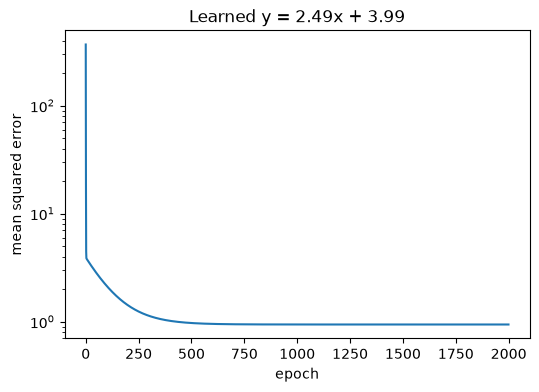

In [19]:
# 19.4 Plot the loss curve (log scale on the y axis shows the whole fall)
w, b, losses = fit_line(x_toy, y_toy)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(losses)
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("mean squared error")
ax.set_title(f"Learned y = {w:.2f}x + {b:.2f}")
plt.show()

## Night 20 · Sat 12 Dec: Probability and statistics basics
A distribution is the shape of your data. Standard deviation is the typical distance from the mean. A classifier
estimates a conditional probability, like P(survived | female).

In [20]:
# 20.1 Simulate, then summarize by hand
def coin_flips(n, seed=0):
    """Flip a fair coin n times with rng = np.random.default_rng(seed) and rng.integers(0, 2, size=n).
    Return the share of heads (1s)."""
    rng = np.random.default_rng(seed)
    return float((rng.integers(0, 2, size=n) == 1).mean())


def mean_var_std(values):
    """Return (mean, variance, standard deviation) computed by hand with sum() and len(), no NumPy.
    Use the population variance: the average squared distance from the mean."""
    mean = sum(values) / len(values)
    variance = sum((v - mean) ** 2 for v in values) / len(values)
    return mean, variance, variance ** 0.5


def z_scores(values):
    """Return (x - mean) / std for each value, as a NumPy array."""
    values = np.asarray(values, dtype=float)
    return (values - values.mean()) / values.std()

data = [2, 4, 4, 4, 5, 5, 7, 9]
check("100,000 flips land close to half heads", lambda: abs(coin_flips(100_000) - 0.5) < 0.01, True)
check("mean, variance, std", lambda: mean_var_std(data), (5.0, 4.0, 2.0))
check("z_scores", lambda: z_scores(data), np.array([-1.5, -0.5, -0.5, -0.5, 0.0, 0.0, 1.0, 2.0]))

✅ Correct: 100,000 flips land close to half heads
✅ Correct: mean, variance, std
✅ Correct: z_scores


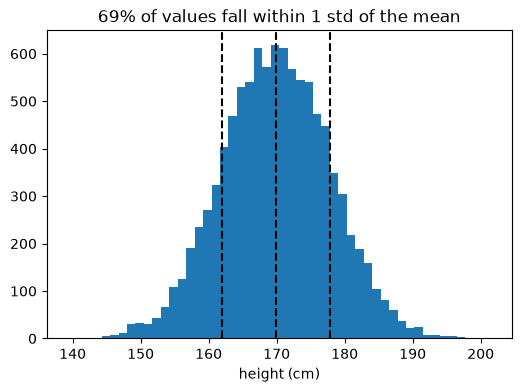

In [21]:
# 20.2 The normal distribution: 10,000 made-up heights with mean 170 cm and standard deviation 8 cm
rng = np.random.default_rng(1)
heights = rng.normal(170, 8, 10_000)
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(heights, bins=50)
for line in [heights.mean() - heights.std(), heights.mean(), heights.mean() + heights.std()]:
    ax.axvline(line, linestyle="--", color="black")
share = ((heights > heights.mean() - heights.std()) & (heights < heights.mean() + heights.std())).mean()
ax.set_title(f"{share:.0%} of values fall within 1 std of the mean")
ax.set_xlabel("height (cm)")
plt.show()

In [22]:
titanic = pd.read_csv(DATA / "titanic.csv")

In [23]:
# 20.3 Conditional probability
def conditional_survival(df, sex):
    """Return P(survived | sex) from the Titanic data, as a fraction between 0 and 1."""
    return float(df.loc[df["sex"] == sex, "survived"].mean())

check("P(survived | female)", lambda: round(conditional_survival(titanic, "female"), 3), 0.742)
check("P(survived | male)", lambda: round(conditional_survival(titanic, "male"), 3), 0.189)

✅ Correct: P(survived | female)
✅ Correct: P(survived | male)


## Night 21 · Sun 13 Dec: Review and project: linear regression from scratch
Predict a penguin's body mass from its flipper length with your own gradient descent from Night 19.
Standardize the input first, so one learning rate suits both w and b.

In [24]:
penguins = pd.read_csv(DATA / "penguins.csv").dropna(subset=["flipper_length_mm", "body_mass_g"])
flipper = penguins["flipper_length_mm"].to_numpy(dtype=float)
mass = penguins["body_mass_g"].to_numpy(dtype=float)
print(len(flipper), "penguins")

342 penguins


In [25]:
# 21.1 Helpers
def standardize(values):
    """Return (values - mean) / std."""
    return (values - values.mean()) / values.std()


def mae(y_true, y_pred):
    """Mean absolute error: the average size of the mistakes."""
    return float(np.abs(np.asarray(y_true) - np.asarray(y_pred)).mean())


def predict_mass(flipper_mm, w, b, mean, std):
    """Predict body mass (g) for a flipper length in mm, with a model trained on standardized input."""
    return w * (flipper_mm - mean) / std + b

check("standardize gives mean 0, std 1", lambda: [round(float(standardize(flipper).mean()), 6), round(float(standardize(flipper).std()), 6)], [0.0, 1.0])
check("mae", lambda: mae([1, 2, 3], [2, 2, 2]), 2 / 3)
check("predict_mass", lambda: predict_mass(200, 697.64, 4201.75, 200.915, 14.041), 4156.3, tol=0.1)

✅ Correct: standardize gives mean 0, std 1
✅ Correct: mae
✅ Correct: predict_mass


In [26]:
# 21.2 Train, compare with NumPy's answer, and measure the error
try:
    x = standardize(flipper)
    w, b, losses = fit_line(x, mass, lr=0.1, epochs=500)
    w_np, b_np = np.polyfit(x, mass, 1)
    print(f"gradient descent: w = {w:.2f}, b = {b:.2f}")
    print(f"np.polyfit:       w = {w_np:.2f}, b = {b_np:.2f}")
    print(f"mean absolute error: {mae(mass, w * x + b):.0f} g")
    guess = predict_mass(200, w, b, flipper.mean(), flipper.std())
    print(f"a penguin with 200 mm flippers: about {guess:,.0f} g")
except NotImplementedError:
    print("Finish standardize(), mae(), predict_mass() and fit_line() (Night 19) first.")

gradient descent: w = 697.64, b = 4201.75
np.polyfit:       w = 697.64, b = 4201.75
mean absolute error: 313 g
a penguin with 200 mm flippers: about 4,156 g


In [27]:
check("your w matches np.polyfit", lambda: abs(w - w_np) < 1, True)
check("mean absolute error is about 313 g", lambda: round(mae(mass, w * x + b)), 313)

✅ Correct: your w matches np.polyfit
✅ Correct: mean absolute error is about 313 g


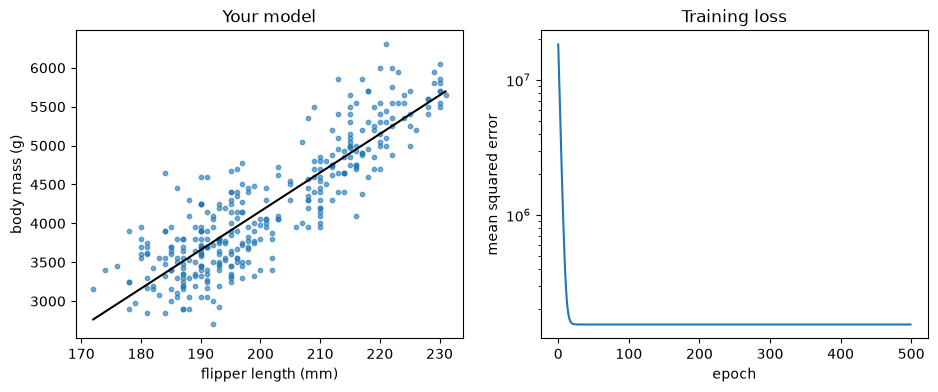

In [28]:
# 21.3 Plot the data with your line, and the loss curve
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.scatter(flipper, mass, s=10, alpha=0.6)
order = np.argsort(flipper)
left.plot(flipper[order], (w * x + b)[order], color="black")
left.set_xlabel("flipper length (mm)")
left.set_ylabel("body mass (g)")
left.set_title("Your model")
right.plot(losses)
right.set_yscale("log")
right.set_xlabel("epoch")
right.set_ylabel("mean squared error")
right.set_title("Training loss")
plt.show()

You just built the loop inside every ML model: predict, measure the loss, follow the gradient, repeat.
Push your work, then tick off Week 3 in the study guide.